# Model Training and Evaluation

This notebook trains and compares models for the three prediction tasks in the assignment:

1. Facial identity classification using HOG image features.
2. Voice identification using MFCC, spectral roll-off and RMS-energy features.
3. Product-category prediction using customer transaction and social-profile features.

The face and voice datasets contain only a small number of original samples. Their test results are useful for showing that the pipeline works, but they are not enough to prove that the models would perform reliably with new people or different recording conditions.

Augmented versions of the same original image or recording are kept in the same data split so that similar copies do not appear in both training and testing.

## 1. Imports and paths

The libraries used for preprocessing, training the classifiers and calculating the evaluation metrics are imported. The feature CSV files created in the previous notebooks are then loaded.

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    log_loss
)
from sklearn.base import clone
import joblib

warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
PROCESSED = DATA / "processed"
IMAGE_FEATURES_PATH = DATA / "images" / "processed" / "image_features.csv"
AUDIO_FEATURES_PATH = DATA / "audio" / "processed" / "audio_features.csv"
TABULAR_FEATURES_PATH = PROCESSED / "tabular_model_features.csv"
MERGED_PATH = PROCESSED / "customer_transactions_social_merged.csv"
MODEL_DIR = ROOT / "models"
REPORT_DIR = PROCESSED / "model_evaluation"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("Python:", sys.version.split()[0])
print("Project root:", ROOT)
for path in [IMAGE_FEATURES_PATH, AUDIO_FEATURES_PATH, TABULAR_FEATURES_PATH, MERGED_PATH]:
    print(path.relative_to(ROOT), "exists:", path.exists())

Python: 3.14.6
Project root: c:\Users\a\Documents\formative_2_data_processing_personal
data\images\processed\image_features.csv exists: True
data\audio\processed\audio_features.csv exists: True
data\processed\tabular_model_features.csv exists: True
data\processed\customer_transactions_social_merged.csv exists: True


## 2. Evaluation measures

The models are compared using accuracy, weighted precision, weighted recall and weighted F1-score. Log loss is also calculated when a model provides class probabilities. Classification reports and confusion matrices show which classes are predicted correctly and where errors occur.

In [2]:
evaluation_rows = []

def evaluate_classifier(task, model_name, model, X_train, y_train, X_test, y_test,
                        save_name, class_names=None):
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test) if hasattr(model, "predict_proba") else None

    metrics = {
        "task": task,
        "model": model_name,
        "test_samples": len(y_test),
        "accuracy": accuracy_score(y_test, predictions),
        "precision_weighted": precision_score(y_test, predictions, average="weighted", zero_division=0),
        "recall_weighted": recall_score(y_test, predictions, average="weighted", zero_division=0),
        "f1_weighted": f1_score(y_test, predictions, average="weighted", zero_division=0),
        "log_loss": log_loss(y_test, probabilities, labels=model.classes_) if probabilities is not None else np.nan
    }
    evaluation_rows.append(metrics)
    print(f"--- {task}: {model_name} ---")
    display(pd.Series(metrics).to_frame("value"))
    print(classification_report(y_test, predictions, zero_division=0))

    labels = model.classes_
    display_labels = class_names if class_names is not None else labels
    cm = confusion_matrix(y_test, predictions, labels=labels)
    cm_display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=display_labels
    )
    cm_display.plot(xticks_rotation=45, cmap="Blues")
    plt.tight_layout()
    plt.show()
    joblib.dump(model, MODEL_DIR / save_name)
    return model, predictions

## 3. Facial identity classification

The image feature table contains original images and augmented versions. To reduce data leakage, variations from each original image are kept together. One original image for each participant is held out for testing, while the remaining originals and their augmented versions are used for training.

There are only four held-out face images, so the evaluation results should be treated as a small demonstration rather than a reliable estimate of face-recognition performance.

In [3]:
if not IMAGE_FEATURES_PATH.exists():
    raise FileNotFoundError("Run the image preprocessing notebook first.")

image_df = pd.read_csv(IMAGE_FEATURES_PATH)
required_image_cols = {"source_path", "participant_id", "augmentation"}
missing = required_image_cols - set(image_df.columns)
if missing:
    raise ValueError(f"Image feature CSV is missing columns: {sorted(missing)}")

hog_cols = [c for c in image_df.columns if c.startswith("hog_")]
if not hog_cols:
    raise ValueError("No HOG feature columns were found.")

original_images = image_df[image_df["augmentation"].eq("original")].copy()
participant_sources = {
    participant: sorted(group["source_path"].unique())
    for participant, group in original_images.groupby("participant_id")
}
print("Original face images by participant:")
display(pd.Series({k: len(v) for k, v in participant_sources.items()}, name="original_images").to_frame())

if len(participant_sources) < 2 or any(len(paths) < 2 for paths in participant_sources.values()):
    raise ValueError(
        "Each participant needs at least two successfully processed original face images "
        "to create a leakage-safe train/test split. Collect more images or fix skipped images."
    )

face_test_sources = {participant: paths[-1] for participant, paths in participant_sources.items()}
face_test = original_images[original_images.apply(
    lambda row: face_test_sources.get(row["participant_id"]) == row["source_path"], axis=1
)].copy()
face_train = image_df[~image_df["source_path"].isin(face_test_sources.values())].copy()

X_face_train = face_train[hog_cols].replace([np.inf, -np.inf], np.nan).fillna(0)
y_face_train = face_train["participant_id"].astype(str)
X_face_test = face_test[hog_cols].replace([np.inf, -np.inf], np.nan).fillna(0)
y_face_test = face_test["participant_id"].astype(str)

print("Training rows (originals + training-only augmentations):", len(face_train))
print("Held-out original face images:", len(face_test))
print("Held-out participants:", sorted(y_face_test.unique()))

Original face images by participant:


,original_images
participant_01,3
participant_02,3
participant_03,3
participant_04,3


Training rows (originals + training-only augmentations): 40
Held-out original face images: 4
Held-out participants: ['participant_01', 'participant_02', 'participant_03', 'participant_04']


--- facial_identity: HOG + linear SVM ---


,value
task,facial_identity
model,HOG + linear SVM
test_samples,4
accuracy,1.0
precision_weighted,1.0
recall_weighted,1.0
f1_weighted,1.0
log_loss,0.462495


                precision    recall  f1-score   support

participant_01       1.00      1.00      1.00         1
participant_02       1.00      1.00      1.00         1
participant_03       1.00      1.00      1.00         1
participant_04       1.00      1.00      1.00         1

      accuracy                           1.00         4
     macro avg       1.00      1.00      1.00         4
  weighted avg       1.00      1.00      1.00         4



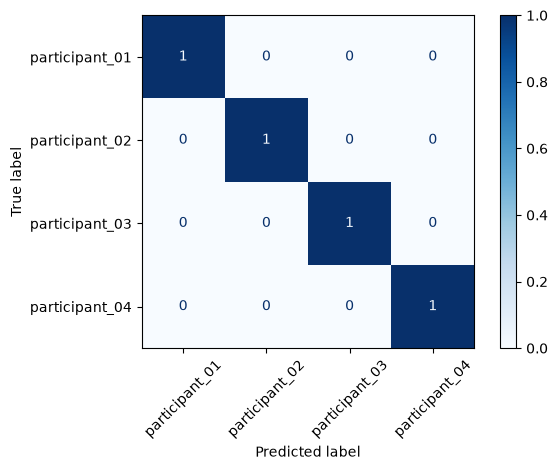

--- facial_identity: HOG + Random Forest ---


,value
task,facial_identity
model,HOG + Random Forest
test_samples,4
accuracy,1.0
precision_weighted,1.0
recall_weighted,1.0
f1_weighted,1.0
log_loss,0.545324


                precision    recall  f1-score   support

participant_01       1.00      1.00      1.00         1
participant_02       1.00      1.00      1.00         1
participant_03       1.00      1.00      1.00         1
participant_04       1.00      1.00      1.00         1

      accuracy                           1.00         4
     macro avg       1.00      1.00      1.00         4
  weighted avg       1.00      1.00      1.00         4



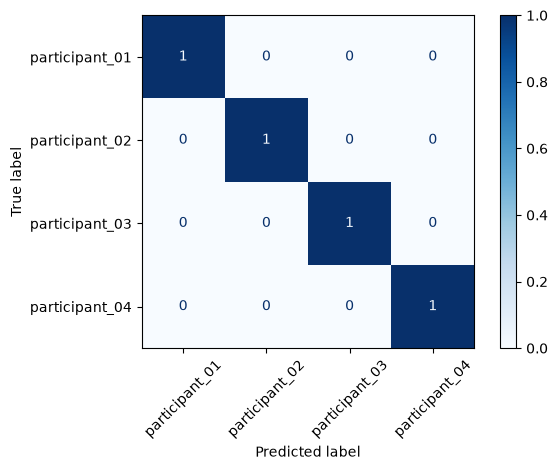

In [4]:
face_models = {
    "HOG + linear SVM": Pipeline([
        ("scale", StandardScaler()),
        ("classifier", SVC(kernel="linear", class_weight="balanced", probability=True, random_state=42))
    ]),
    "HOG + Random Forest": RandomForestClassifier(
        n_estimators=300, class_weight="balanced", random_state=42,
        min_samples_leaf=1, n_jobs=-1
    )
}

for name, model in face_models.items():
    evaluate_classifier(
        "facial_identity", name, model,
        X_face_train, y_face_train, X_face_test, y_face_test,
        "face_" + ("svm" if "SVM" in name else "random_forest") + ".joblib"
    )

## 4. Voice identification

Each participant has two original recordings, one for each phrase. The models are trained using the `yes_approve` recordings and their augmented versions, then tested using the original `confirm_transaction` recordings.

This split checks whether the models can identify the speaker when the phrase is different from the one used for training. There are only four held-out recordings, so the scores are very uncertain.

In [5]:
if not AUDIO_FEATURES_PATH.exists():
    raise FileNotFoundError("Run the audio preprocessing notebook first.")

audio_df = pd.read_csv(AUDIO_FEATURES_PATH)
required_audio_cols = {"source_path", "participant_id", "phrase", "augmentation"}
missing = required_audio_cols - set(audio_df.columns)
if missing:
    raise ValueError(f"Audio feature CSV is missing columns: {sorted(missing)}")

audio_meta = {"audio_path", "source_path", "participant_id", "phrase", "augmentation"}
audio_feature_cols = [
    c for c in audio_df.columns
    if c not in audio_meta and pd.api.types.is_numeric_dtype(audio_df[c])
]
if not audio_feature_cols:
    raise ValueError("No numeric audio feature columns were found.")

audio_originals = audio_df[audio_df["augmentation"].eq("original")].copy()
train_source_paths, test_source_paths = [], []
for participant, group in audio_originals.groupby("participant_id"):
    phrase_map = group.groupby("phrase")["source_path"].first().to_dict()
    if "yes_approve" not in phrase_map or "confirm_transaction" not in phrase_map:
        raise ValueError(
            f"{participant} needs one original recording for each required phrase."
        )
    train_source_paths.append(phrase_map["yes_approve"])
    test_source_paths.append(phrase_map["confirm_transaction"])

voice_train = audio_df[audio_df["source_path"].isin(train_source_paths)].copy()
voice_test = audio_originals[audio_originals["source_path"].isin(test_source_paths)].copy()

X_voice_train = voice_train[audio_feature_cols].replace([np.inf, -np.inf], np.nan).fillna(0)
y_voice_train = voice_train["participant_id"].astype(str)
X_voice_test = voice_test[audio_feature_cols].replace([np.inf, -np.inf], np.nan).fillna(0)
y_voice_test = voice_test["participant_id"].astype(str)

print("Training rows (one phrase + its augmentations per participant):", len(voice_train))
print("Held-out original recordings (other phrase):", len(voice_test))
display(voice_test[["participant_id", "phrase", "augmentation"]])

Training rows (one phrase + its augmentations per participant): 24
Held-out original recordings (other phrase): 4


,participant_id,phrase,augmentation
0,participant_01,confirm_transaction,original
12,participant_02,confirm_transaction,original
24,participant_03,confirm_transaction,original
36,participant_04,confirm_transaction,original


--- voiceprint_identification: MFCC + RBF SVM ---


,value
task,voiceprint_identification
model,MFCC + RBF SVM
test_samples,4
accuracy,1.0
precision_weighted,1.0
recall_weighted,1.0
f1_weighted,1.0
log_loss,0.959158


                precision    recall  f1-score   support

participant_01       1.00      1.00      1.00         1
participant_02       1.00      1.00      1.00         1
participant_03       1.00      1.00      1.00         1
participant_04       1.00      1.00      1.00         1

      accuracy                           1.00         4
     macro avg       1.00      1.00      1.00         4
  weighted avg       1.00      1.00      1.00         4



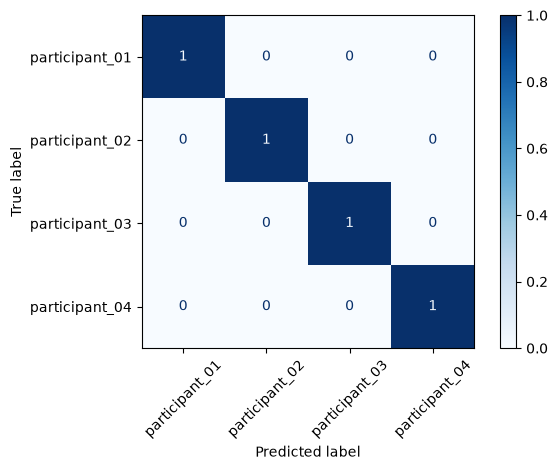

--- voiceprint_identification: MFCC + Random Forest ---


,value
task,voiceprint_identification
model,MFCC + Random Forest
test_samples,4
accuracy,1.0
precision_weighted,1.0
recall_weighted,1.0
f1_weighted,1.0
log_loss,0.61351


                precision    recall  f1-score   support

participant_01       1.00      1.00      1.00         1
participant_02       1.00      1.00      1.00         1
participant_03       1.00      1.00      1.00         1
participant_04       1.00      1.00      1.00         1

      accuracy                           1.00         4
     macro avg       1.00      1.00      1.00         4
  weighted avg       1.00      1.00      1.00         4



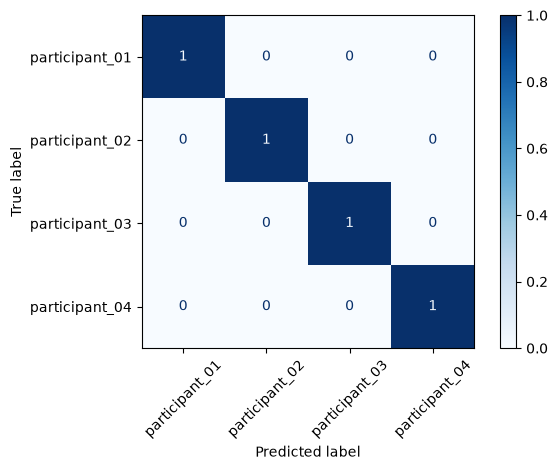

In [6]:
voice_models = {
    "MFCC + RBF SVM": Pipeline([
        ("scale", StandardScaler()),
        ("classifier", SVC(kernel="rbf", class_weight="balanced", probability=True, random_state=42))
    ]),
    "MFCC + Random Forest": RandomForestClassifier(
        n_estimators=300, class_weight="balanced", random_state=42,
        min_samples_leaf=1, n_jobs=-1
    )
}

for name, model in voice_models.items():
    evaluate_classifier(
        "voiceprint_identification", name, model,
        X_voice_train, y_voice_train, X_voice_test, y_voice_test,
        "voice_" + ("svm" if "SVM" in name else "random_forest") + ".joblib"
    )

## 5. Product-category prediction

The target for this task is `product_category`. The numeric and categorical columns are prepared using imputation and encoding, then Logistic Regression is compared with Random Forest.

A customer can have multiple transactions, so customer ID is used as the grouping variable in `StratifiedGroupKFold`. This helps prevent transactions from the same customer from appearing in both the training and test groups.

In [7]:
if not TABULAR_FEATURES_PATH.exists() or not MERGED_PATH.exists():
    raise FileNotFoundError("Run the tabular preprocessing notebook first.")

tabular_Xy = pd.read_csv(TABULAR_FEATURES_PATH)
merged_for_groups = pd.read_csv(MERGED_PATH)

target = "product_category"
group_col = "customer_id_legacy"
if target not in tabular_Xy or group_col not in merged_for_groups:
    raise ValueError("The model feature table or merged table is missing its target/group column.")
if len(tabular_Xy) != len(merged_for_groups):
    raise ValueError("Feature rows do not align with merged transaction rows.")

y_product = tabular_Xy[target].astype(str)
groups = merged_for_groups[group_col].astype(str)

excluded_predictors = {
    target, "transaction_id", "customer_id_legacy", "customer_id_candidate",
    "customer_id_new", "purchase_amount", "customer_rating", "purchase_date"
}
X_product = tabular_Xy.drop(columns=[c for c in excluded_predictors if c in tabular_Xy.columns])
numeric_cols = X_product.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X_product.select_dtypes(exclude=np.number).columns.tolist()

preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_cols),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_cols)
])

product_models = {
    "Logistic Regression": Pipeline([
        ("preprocess", preprocessor),
        ("classifier", LogisticRegression(max_iter=3000, class_weight="balanced"))
    ]),
    "Random Forest": Pipeline([
        ("preprocess", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=400, class_weight="balanced", random_state=42,
            min_samples_leaf=2, n_jobs=-1
        ))
    ])
}

splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_idx, test_idx = next(splitter.split(X_product, y_product, groups))
X_product_train, X_product_test = X_product.iloc[train_idx], X_product.iloc[test_idx]
y_product_train, y_product_test = y_product.iloc[train_idx], y_product.iloc[test_idx]
groups_train = groups.iloc[train_idx]

print("Rows:", len(X_product))
print("Train rows:", len(train_idx), "Test rows:", len(test_idx))
print("Train classes:", sorted(y_product_train.unique()))
print("Test classes:", sorted(y_product_test.unique()))
print("Customer groups overlap:", bool(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])))
display(y_product.value_counts().rename("count").to_frame())

Rows: 150
Train rows: 119 Test rows: 31
Train classes: ['Books', 'Clothing', 'Electronics', 'Groceries', 'Sports']
Test classes: ['Books', 'Clothing', 'Electronics', 'Groceries', 'Sports']
Customer groups overlap: False


,count
product_category,
Sports,35
Electronics,34
Clothing,28
Groceries,28
Books,25


--- product_category: Logistic Regression ---


,value
task,product_category
model,Logistic Regression
test_samples,31
accuracy,0.225806
precision_weighted,0.164516
recall_weighted,0.225806
f1_weighted,0.189374
log_loss,2.179532


              precision    recall  f1-score   support

       Books       0.00      0.00      0.00         5
    Clothing       0.33      0.50      0.40         6
 Electronics       0.30      0.43      0.35         7
   Groceries       0.17      0.17      0.17         6
      Sports       0.00      0.00      0.00         7

    accuracy                           0.23        31
   macro avg       0.16      0.22      0.18        31
weighted avg       0.16      0.23      0.19        31



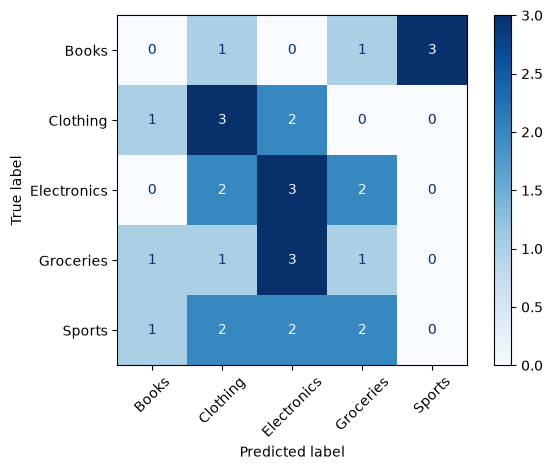

--- product_category: Random Forest ---


,value
task,product_category
model,Random Forest
test_samples,31
accuracy,0.225806
precision_weighted,0.120968
recall_weighted,0.225806
f1_weighted,0.155961
log_loss,1.808722


              precision    recall  f1-score   support

       Books       0.00      0.00      0.00         5
    Clothing       0.33      0.50      0.40         6
 Electronics       0.25      0.57      0.35         7
   Groceries       0.00      0.00      0.00         6
      Sports       0.00      0.00      0.00         7

    accuracy                           0.23        31
   macro avg       0.12      0.21      0.15        31
weighted avg       0.12      0.23      0.16        31



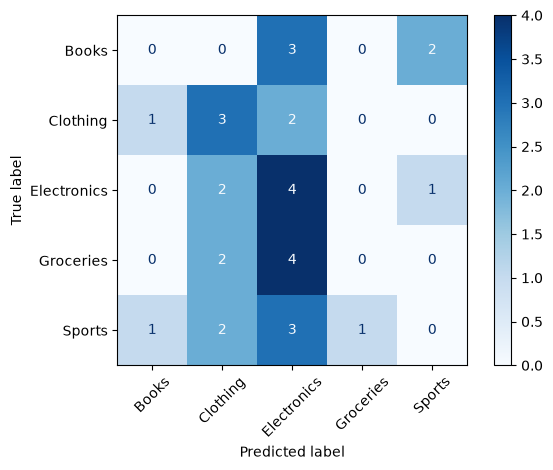

,model,cv_accuracy_mean,cv_accuracy_std,cv_f1_weighted_mean,cv_f1_weighted_std
0,Logistic Regression,0.192747,0.035994,0.180794,0.015836
1,Random Forest,0.213667,0.042001,0.184971,0.052568


In [8]:
for name, model in product_models.items():
    evaluate_classifier(
        "product_category", name, model,
        X_product_train, y_product_train, X_product_test, y_product_test,
        "product_" + ("logistic_regression" if "Logistic" in name else "random_forest") + ".joblib"
    )

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
cv_rows = []
for name, model in product_models.items():
    scores = cross_validate(
        clone(model), X_product, y_product, groups=groups, cv=cv,
        scoring={"accuracy": "accuracy", "f1_weighted": "f1_weighted"},
        return_train_score=False, n_jobs=-1
    )
    cv_rows.append({
        "model": name,
        "cv_accuracy_mean": scores["test_accuracy"].mean(),
        "cv_accuracy_std": scores["test_accuracy"].std(),
        "cv_f1_weighted_mean": scores["test_f1_weighted"].mean(),
        "cv_f1_weighted_std": scores["test_f1_weighted"].std()
    })
cv_results = pd.DataFrame(cv_rows)
display(cv_results)

## 6. Compare the model results

The evaluation results are brought together so that the models can be compared. The face and voice test sets contain far fewer samples than the product-category test set, so their scores should not be compared as if they were measured under the same conditions.

In [9]:
results_df = pd.DataFrame(evaluation_rows)
display(results_df.sort_values(["task", "f1_weighted"], ascending=[True, False]))
results_path = REPORT_DIR / "model_metrics.csv"
cv_path = REPORT_DIR / "product_grouped_cross_validation.csv"
results_df.to_csv(results_path, index=False)
cv_results.to_csv(cv_path, index=False)
print("Saved:", results_path)
print("Saved:", cv_path)

,task,model,test_samples,accuracy,precision_weighted,recall_weighted,f1_weighted,log_loss
0,facial_identity,HOG + linear SVM,4,1.000000,1.000000,1.000000,1.000000,0.462495
1,facial_identity,HOG + Random Forest,4,1.000000,1.000000,1.000000,1.000000,0.545324
4,product_category,Logistic Regression,31,0.225806,0.164516,0.225806,0.189374,2.179532
5,product_category,Random Forest,31,0.225806,0.120968,0.225806,0.155961,1.808722
2,voiceprint_identification,MFCC + RBF SVM,4,1.000000,1.000000,1.000000,1.000000,0.959158
3,voiceprint_identification,MFCC + Random Forest,4,1.000000,1.000000,1.000000,1.000000,0.613510


Saved: c:\Users\a\Documents\formative_2_data_processing_personal\data\processed\model_evaluation\model_metrics.csv
Saved: c:\Users\a\Documents\formative_2_data_processing_personal\data\processed\model_evaluation\product_grouped_cross_validation.csv


## 7. What the results mean and what is missing

The face and voice models achieved perfect scores on their small held-out test sets. However, each test set contains only four original samples, so these results do not show how well the models would work with a larger group.

The product-category models performed much less well. There are five target categories, and the accuracy was only a little above the 20% random-choice baseline. The current features and amount of data are not enough for strong product predictions.

Augmented rows are not independent samples, so they must not be randomly divided between training and testing. The transaction simulation is the next step: it checks the face and voice predictions before showing the product-category result.

## 8. Multimodal transaction decision logic

The transaction process combines the outputs of the facial identity model and the voiceprint model. The claimed account name is first converted to its participant ID. The uploaded image is processed into HOG features, while the WAV recording is converted into the MFCC, spectral roll-off, RMS-energy and duration features used during training.

Each biometric model returns a predicted participant and a probability estimate. A prediction is treated as unknown when its confidence is below the configured demonstration threshold of 0.60. A biometric check passes only when the prediction is above the threshold and matches the claimed participant ID.

The transaction is authorised only when both the face check and voice check pass. If either model predicts a different participant, returns unknown, or falls below the threshold, the transaction is rejected and product prediction is not run. This AND-gate prevents one successful biometric result from overriding a failed second check.

After both checks pass, the product-category model receives customer features associated with the verified participant. The participant-to-customer mapping must be confirmed from the project data before this final personalised step is enabled. The current demonstration models are trained on a small dataset, and the confidence threshold is a classroom demonstration setting rather than a validated security threshold.
